# STAGE 2 — TASK 2: PHÂN CỤM SUẤT CHIẾU CGV BẰNG K-MEANS

**Hướng phân tích:** Phân cụm suất chiếu/phim CGV 

## Mục tiêu theo yêu cầu Task 2
1. Chọn số cụm K bằng Elbow (WCSS) và Silhouette Score.
2. Chạy K-Means trên đặc trưng đã chuẩn hóa **không dùng PCA**.
3. Chạy K-Means trên dữ liệu đã giảm chiều bằng PCA.
4. So sánh hai cách biểu diễn dữ liệu bằng WCSS và Silhouette Score.
5. Vẽ biểu đồ phân tán 2D theo nhãn cụm.
6. Gắn `Cluster_Label` trở lại dataset gốc và xuất CSV.

## Trước khi chạy
Đặt notebook này cùng thư mục với các file sau:
- `cgv_eda_cleaned.csv` — dataset gốc đã làm sạch.
- `cgv_features_scaled.csv` — đặc trưng đã chuẩn hóa, xuất từ Task 1.
- `cgv_pca_transformed.csv` — dữ liệu PCA, xuất từ Task 1.

Nếu bạn chưa chạy Task 1 hoặc các file xuất ra chưa tồn tại, hãy chạy toàn bộ `Task1_PCA_CGV_HoanChinh.ipynb` trước.


## 1. Import thư viện (chỉ chạy nếu máy chưa có)



In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42


## 2. Đọc dữ liệu từ Task 1 và dataset gốc

Notebook ưu tiên đọc file kết quả của Task 1 để đảm bảo hai mô hình sử dụng đúng cùng một bộ đặc trưng. Các file phải có cùng thứ tự dòng như dataset gốc.


In [6]:
DATA_PATHS = [
    "cgv_eda_cleaned.csv",
    "/mnt/data/cgv_eda_cleaned.csv"
]

ORIGINAL_PATH = next((p for p in DATA_PATHS if os.path.exists(p)), None)
if ORIGINAL_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy dataset gốc. Hãy đặt cgv_eda_cleaned.csv "
        "cùng thư mục với notebook hoặc sửa ORIGINAL_PATH."
    )

df_original = pd.read_csv(ORIGINAL_PATH)

SCALED_PATH = "cgv_features_scaled.csv"
PCA_PATH = "cgv_pca_transformed.csv"

if not os.path.exists(SCALED_PATH):
    raise FileNotFoundError(
        "Không tìm thấy cgv_features_scaled.csv. Hãy chạy Task 1 và xuất file trước."
    )

if not os.path.exists(PCA_PATH):
    raise FileNotFoundError(
        "Không tìm thấy cgv_pca_transformed.csv. Hãy chạy Task 1 và xuất file trước."
    )

X_scaled_df = pd.read_csv(SCALED_PATH)
X_pca_df = pd.read_csv(PCA_PATH)

print("Dataset gốc:", df_original.shape)
print("Đặc trưng chuẩn hóa (không PCA):", X_scaled_df.shape)
print("Đặc trưng PCA:", X_pca_df.shape)

if len(df_original) != len(X_scaled_df) or len(df_original) != len(X_pca_df):
    raise ValueError(
        "Số dòng giữa dataset gốc và file Task 1 không khớp. "
        "Hãy kiểm tra lại thứ tự và cách xuất file."
    )

display(df_original.head())


Dataset gốc: (1172, 15)
Đặc trưng chuẩn hóa (không PCA): (1172, 57)
Đặc trưng PCA: (1172, 25)


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,2D Lồng Tiếng Việt,12:50,"Hôm nay, tôi đã có cơ hội xem suất chiếu LAPUT...",https://www.cgv.vn/default/laputa.html,K,Hayao Miyazaki,"Mayumi Tanaka, Keiko Yokozawa, Kotoe Hatsui, M...",Hoạt Hình,2026-09-25,129 phút,Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,129.0
2,MARNIE YÊU DẤU,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt,16:50,"Hôm nay, tôi đã có cơ hội xem suất chiếu ""MARN...",https://www.cgv.vn/default/marnie-yeu-dau.html,K,Hiromasa Yonebayashi,"Sara Takatsuki, Kasumi Arimura, Hana Sugisaki,...",Hoạt Hình,2026-09-18,103 phút,Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,103.0
3,TRẠI BUÔN NGƯỜI,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh,12:00,"Tôi vừa có dịp xem suất chiếu ""TRẠI BUÔN NGƯỜI...",https://www.cgv.vn/default/trai-buon-nguoi.html,T18,Toni Dương Bảo Anh,"Steven Nguyễn, Quách Ngọc Ngoan, Tùng Mint, Hu...","Hành Động, Hồi hộp",2026-09-25,135 phút,Tiếng Việt,135.0
4,TRẠI BUÔN NGƯỜI,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh,15:10,Trải nghiệm xem suất chiếu TRẠI BUÔN NGƯỜI tại...,https://www.cgv.vn/default/trai-buon-nguoi.html,T18,Toni Dương Bảo Anh,"Steven Nguyễn, Quách Ngọc Ngoan, Tùng Mint, Hu...","Hành Động, Hồi hộp",2026-09-25,135 phút,Tiếng Việt,135.0


## 3. Kiểm tra ma trận đầu vào

K-Means chỉ nhận dữ liệu số. Các file được xuất từ Task 1 đã mã hóa và chuẩn hóa. Cell dưới đây kiểm tra giá trị thiếu và chuyển dữ liệu thành ma trận số.


In [7]:
X_scaled_df = X_scaled_df.apply(pd.to_numeric, errors="coerce")
X_pca_df = X_pca_df.apply(pd.to_numeric, errors="coerce")

if X_scaled_df.isna().any().any() or X_pca_df.isna().any().any():
    raise ValueError("Đầu vào có giá trị thiếu hoặc không phải số. Hãy kiểm tra lại Task 1.")

X_scaled = X_scaled_df.to_numpy(dtype=float)
X_pca = X_pca_df.to_numpy(dtype=float)

print("Giá trị thiếu trong X_scaled:", X_scaled_df.isna().sum().sum())
print("Giá trị thiếu trong X_pca:", X_pca_df.isna().sum().sum())


Giá trị thiếu trong X_scaled: 0
Giá trị thiếu trong X_pca: 0


## 4. Chọn K bằng Elbow (WCSS) và Silhouette Score

- **WCSS / inertia:** tổng bình phương khoảng cách từ các điểm đến tâm cụm. WCSS thường giảm khi K tăng; tìm điểm “khuỷu tay” là một cách chọn K.
- **Silhouette Score:** đánh giá mức độ gần nhau trong cùng cụm và tách biệt với cụm khác. Giá trị gần 1 thường cho thấy cụm tách biệt tốt hơn; gần 0 là cụm chồng lấn; âm có thể cho thấy một số điểm được gán cụm chưa phù hợp.

Để so sánh công bằng, ta tính cả hai chỉ số trên đặc trưng chuẩn hóa và đặc trưng PCA. Silhouette có thể tốn thời gian với dataset lớn; notebook dùng sample tối đa 1.000 dòng khi tính điểm.


In [8]:
# Thử K từ 2 đến tối đa 10, nhưng không vượt số dòng hợp lệ
K_VALUES = list(range(2, min(10, len(df_original) - 1) + 1))
SILHOUETTE_SAMPLE_SIZE = min(1000, len(df_original))

def evaluate_kmeans(X, k_values, label):
    rows = []
    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )
        labels = model.fit_predict(X)

        score = silhouette_score(
            X,
            labels,
            sample_size=SILHOUETTE_SAMPLE_SIZE if len(X) > SILHOUETTE_SAMPLE_SIZE else None,
            random_state=RANDOM_STATE
        )

        rows.append({
            "Representation": label,
            "K": k,
            "WCSS": model.inertia_,
            "Silhouette_Score": score
        })

    return pd.DataFrame(rows)

results_original = evaluate_kmeans(X_scaled, K_VALUES, "Không PCA")
results_pca = evaluate_kmeans(X_pca, K_VALUES, "Có PCA")

results = pd.concat([results_original, results_pca], ignore_index=True)
display(results.round(4))


c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

,Representation,K,WCSS,Silhouette_Score
0,Không PCA,2,60507.7167,0.1749
1,Không PCA,3,57001.3158,0.1757
2,Không PCA,4,53432.4987,0.1843
3,Không PCA,5,48112.1709,0.2414
4,Không PCA,6,45813.6396,0.2418
5,Không PCA,7,41634.2872,0.2677
6,Không PCA,8,39457.7104,0.2998
7,Không PCA,9,36456.4180,0.3209
8,Không PCA,10,34185.4873,0.3435
9,Có PCA,2,50744.8382,0.2071


## 5. Biểu đồ Elbow (WCSS)

### So What? — Ý nghĩa biểu đồ
WCSS giảm khi tăng K vì các điểm được chia thành nhiều cụm nhỏ hơn. Ta tìm vị trí mà mức giảm bắt đầu chậm lại (điểm khuỷu tay), rồi đối chiếu với Silhouette Score. Không nên chọn K chỉ vì WCSS thấp nhất, bởi tăng K gần như luôn làm WCSS giảm.


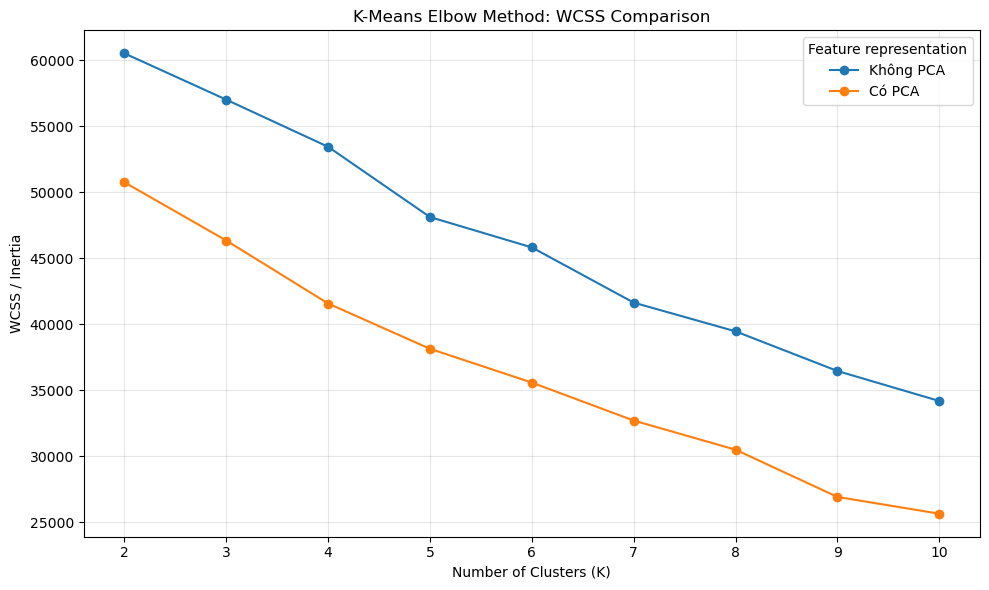

In [9]:
plt.figure(figsize=(10, 6))

for representation in ["Không PCA", "Có PCA"]:
    part = results[results["Representation"] == representation]
    plt.plot(part["K"], part["WCSS"], marker="o", label=representation)

plt.title("K-Means Elbow Method: WCSS Comparison")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(K_VALUES)
plt.grid(True, alpha=0.3)
plt.legend(title="Feature representation")
plt.tight_layout()
plt.show()


## 6. Biểu đồ Silhouette Score

### So What? — Ý nghĩa biểu đồ
Silhouette Score hỗ trợ đánh giá chất lượng phân cụm, có xét đến cả độ gắn kết trong cụm và khoảng cách đến cụm gần nhất. K có điểm cao hơn là một ứng viên tốt, nhưng vẫn cần kiểm tra biểu đồ và ý nghĩa thực tế của từng cụm. Điểm số cao không tự động chứng minh rằng các nhóm có ý nghĩa kinh doanh.


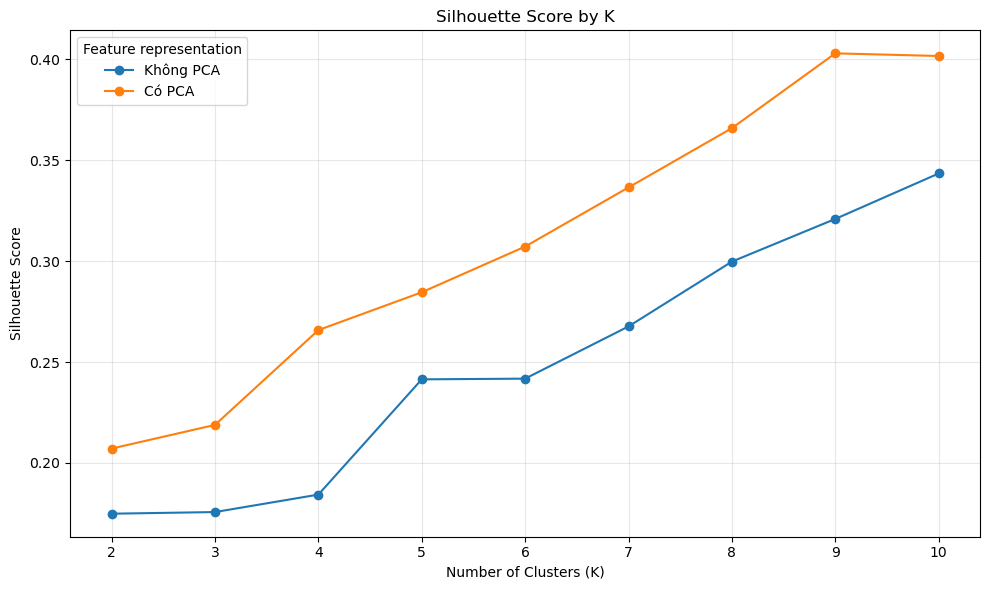

In [10]:
plt.figure(figsize=(10, 6))

for representation in ["Không PCA", "Có PCA"]:
    part = results[results["Representation"] == representation]
    plt.plot(part["K"], part["Silhouette_Score"], marker="o", label=representation)

plt.title("Silhouette Score by K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(K_VALUES)
plt.grid(True, alpha=0.3)
plt.legend(title="Feature representation")
plt.tight_layout()
plt.show()


## 7. Đề xuất K theo Silhouette Score và chọn K cuối cùng

Cell này đề xuất K có Silhouette Score cao nhất cho từng cách biểu diễn. Tuy nhiên, hãy xem thêm Elbow và khả năng giải thích các cụm trước khi quyết định. Bạn có thể sửa `K_CHOSEN` sau khi quan sát biểu đồ.


In [11]:
best_k_original = int(
    results[results["Representation"] == "Không PCA"]
    .sort_values("Silhouette_Score", ascending=False)
    .iloc[0]["K"]
)

best_k_pca = int(
    results[results["Representation"] == "Có PCA"]
    .sort_values("Silhouette_Score", ascending=False)
    .iloc[0]["K"]
)

print("K đề xuất theo Silhouette - không PCA:", best_k_original)
print("K đề xuất theo Silhouette - có PCA:", best_k_pca)

# Chọn K cho kết quả chính. Có thể sửa sau khi xem Elbow và Silhouette.
K_CHOSEN = best_k_pca
print("K được chọn để tạo nhãn Cluster_Label:", K_CHOSEN)


K đề xuất theo Silhouette - không PCA: 10
K đề xuất theo Silhouette - có PCA: 9
K được chọn để tạo nhãn Cluster_Label: 9


## 8. Huấn luyện K-Means với K đã chọn và so sánh hai cách

Để tạo kết quả so sánh, hai mô hình được huấn luyện trên cùng số cụm `K_CHOSEN`. Các nhãn cụm giữa hai mô hình không nhất thiết tương ứng với nhau vì PCA thay đổi không gian khoảng cách.


In [12]:
kmeans_original = KMeans(
    n_clusters=K_CHOSEN,
    random_state=RANDOM_STATE,
    n_init=10
)
labels_original = kmeans_original.fit_predict(X_scaled)

kmeans_pca = KMeans(
    n_clusters=K_CHOSEN,
    random_state=RANDOM_STATE,
    n_init=10
)
labels_pca = kmeans_pca.fit_predict(X_pca)

comparison = pd.DataFrame([
    {
        "Model": "K-Means không PCA",
        "K": K_CHOSEN,
        "WCSS": kmeans_original.inertia_,
        "Silhouette_Score": silhouette_score(
            X_scaled, labels_original,
            sample_size=SILHOUETTE_SAMPLE_SIZE if len(X_scaled) > SILHOUETTE_SAMPLE_SIZE else None,
            random_state=RANDOM_STATE
        )
    },
    {
        "Model": "K-Means có PCA",
        "K": K_CHOSEN,
        "WCSS": kmeans_pca.inertia_,
        "Silhouette_Score": silhouette_score(
            X_pca, labels_pca,
            sample_size=SILHOUETTE_SAMPLE_SIZE if len(X_pca) > SILHOUETTE_SAMPLE_SIZE else None,
            random_state=RANDOM_STATE
        )
    }
])

display(comparison.round(4))


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


,Model,K,WCSS,Silhouette_Score
0,K-Means không PCA,9,36456.4180,0.3209
1,K-Means có PCA,9,26920.7409,0.4030


### Nhận xét:
- Về Silhouette Score: Mô hình có PCA đạt 0,4030, cao hơn mô hình không PCA đạt 0,3209. Điều này cho thấy các cụm trên không gian PCA có xu hướng gắn kết và tách biệt tốt hơn theo thước đo Silhouette.
- Về WCSS: Mô hình có PCA có WCSS thấp hơn. Tuy nhiên, hai mô hình làm việc trong không gian có số chiều khác nhau, nên không thể chỉ dựa vào WCSS để kết luận mô hình PCA tốt hơn. Silhouette Score là căn cứ so sánh hữu ích hơn trong trường hợp này.
- Về số chiều: PCA giảm số chiều từ 57 xuống 25, tương đương giảm khoảng 56,14%, giúp mô hình làm việc với ít đặc trưng hơn mà vẫn giữ lại 85,38% phương sai từ Task 1.


## 9. Trực quan hóa cụm 2D

- Với mô hình **có PCA**, nếu có ít nhất 2 thành phần, dùng PC1 và PC2.
- Với mô hình **không PCA**, dùng PCA 2 thành phần chỉ để hiển thị; nhãn cụm vẫn lấy từ K-Means được huấn luyện trên `X_scaled`.

Điều này giúp so sánh trực quan mà không nhầm lẫn: mô hình không PCA không được huấn luyện trên không gian 2D này.


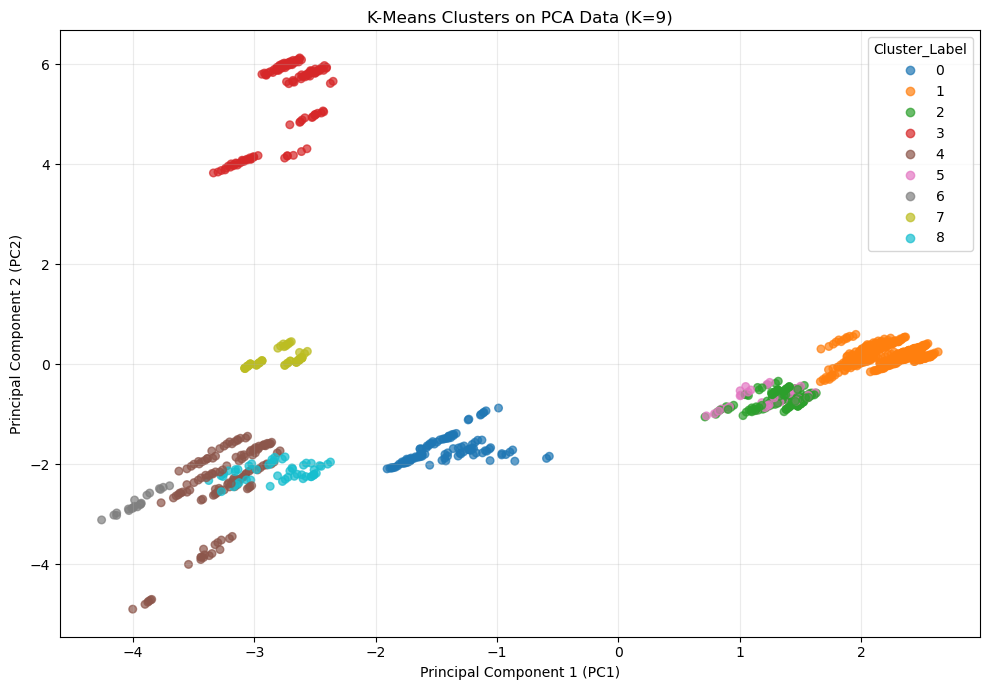

In [13]:
# Biểu đồ cụm từ mô hình K-Means có PCA
if X_pca.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=labels_pca, cmap="tab10", alpha=0.7, s=30
    )
    plt.title(f"K-Means Clusters on PCA Data (K={K_CHOSEN})")
    plt.xlabel("Principal Component 1 (PC1)")
    plt.ylabel("Principal Component 2 (PC2)")
    plt.legend(*scatter.legend_elements(), title="Cluster_Label")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Dữ liệu PCA có dưới 2 thành phần; không thể vẽ biểu đồ 2D.")


### So What? — Biểu đồ K-Means trên PCA
Mỗi màu biểu thị một cụm mà K-Means tìm được trong không gian PCA. Các nhóm tách biệt rõ có thể cho thấy các suất chiếu có cấu trúc đặc trưng khác nhau; vùng chồng lấn cho thấy một số suất chiếu tương đồng theo các chiều đang hiển thị. Đây là phép chiếu 2D nên không thể hiện đầy đủ các thành phần PCA còn lại. Hãy kết hợp biểu đồ với Silhouette Score và bảng mô tả đặc trưng từng cụm trước khi đặt tên cho chúng.


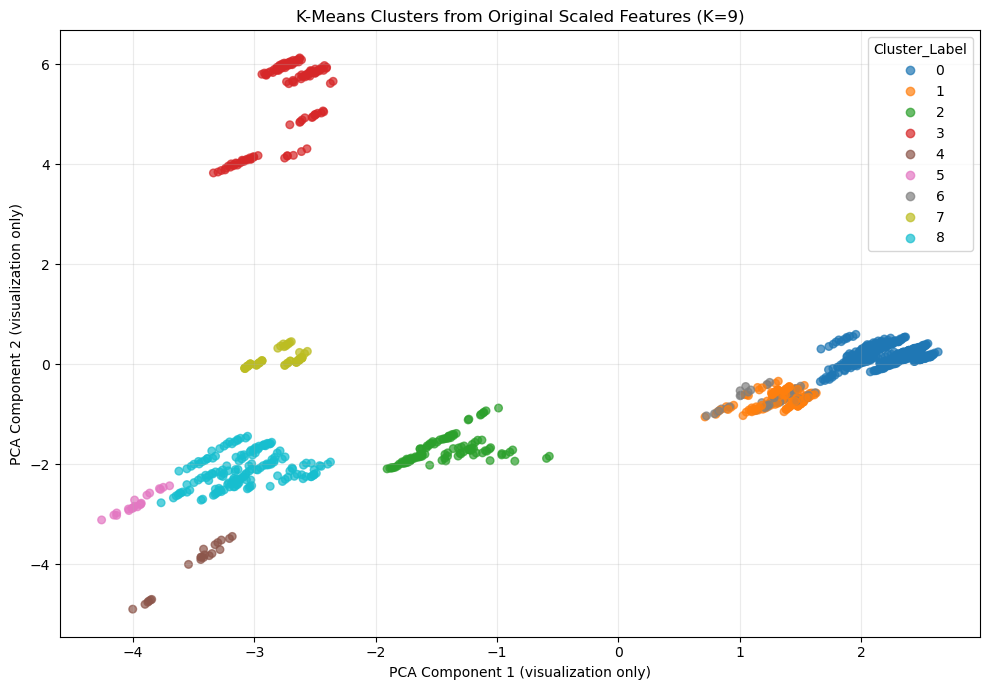

In [14]:
# PCA 2D chỉ dùng để trình bày; nhãn được tạo từ K-Means không PCA
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_scaled_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_scaled_2d[:, 0], X_scaled_2d[:, 1],
    c=labels_original, cmap="tab10", alpha=0.7, s=30
)
plt.title(f"K-Means Clusters from Original Scaled Features (K={K_CHOSEN})")
plt.xlabel("PCA Component 1 (visualization only)")
plt.ylabel("PCA Component 2 (visualization only)")
plt.legend(*scatter.legend_elements(), title="Cluster_Label")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


### So What? — Nhãn không PCA được chiếu để hiển thị
Màu sắc ở đây là nhãn từ mô hình được huấn luyện trên toàn bộ đặc trưng chuẩn hóa, còn trục X/Y chỉ là phép chiếu 2D để quan sát. Vì thế, các điểm cùng màu có thể chồng lấn trên hình mà vẫn được phân biệt trong không gian nhiều chiều. Không nên kết luận chất lượng mô hình chỉ dựa vào hình chiếu này.


## 10. Gắn Cluster_Label vào dataset gốc và xuất kết quả

Notebook gắn nhãn từ mô hình K-Means có PCA vào dataset gốc.


In [15]:
labels_final = labels_pca

df_result = df_original.copy()
df_result["Cluster_Label"] = labels_final

df_result.to_csv(
    "cgv_clustered_suatchieu.csv",
    index=False,
    encoding="utf-8-sig"
)

cluster_counts = (
    df_result["Cluster_Label"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster_Label")
    .reset_index(name="Number_of_Showtimes")
)

cluster_counts["Percentage"] = (
    cluster_counts["Number_of_Showtimes"] / len(df_result) * 100
)

print("Đã lưu: cgv_clustered_suatchieu.csv")
display(cluster_counts.round(2))
display(df_result.head())


Đã lưu: cgv_clustered_suatchieu.csv


,Cluster_Label,Number_of_Showtimes,Percentage
0,0,110,9.39
1,1,488,41.64
2,2,136,11.60
3,3,130,11.09
4,4,134,11.43
5,5,49,4.18
6,6,20,1.71
7,7,54,4.61
8,8,51,4.35


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes,Cluster_Label
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0,3
1,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,2D Lồng Tiếng Việt,12:50,"Hôm nay, tôi đã có cơ hội xem suất chiếu LAPUT...",https://www.cgv.vn/default/laputa.html,K,Hayao Miyazaki,"Mayumi Tanaka, Keiko Yokozawa, Kotoe Hatsui, M...",Hoạt Hình,2026-09-25,129 phút,Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,129.0,4
2,MARNIE YÊU DẤU,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt,16:50,"Hôm nay, tôi đã có cơ hội xem suất chiếu ""MARN...",https://www.cgv.vn/default/marnie-yeu-dau.html,K,Hiromasa Yonebayashi,"Sara Takatsuki, Kasumi Arimura, Hana Sugisaki,...",Hoạt Hình,2026-09-18,103 phút,Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,103.0,4
3,TRẠI BUÔN NGƯỜI,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh,12:00,"Tôi vừa có dịp xem suất chiếu ""TRẠI BUÔN NGƯỜI...",https://www.cgv.vn/default/trai-buon-nguoi.html,T18,Toni Dương Bảo Anh,"Steven Nguyễn, Quách Ngọc Ngoan, Tùng Mint, Hu...","Hành Động, Hồi hộp",2026-09-25,135 phút,Tiếng Việt,135.0,1
4,TRẠI BUÔN NGƯỜI,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh,15:10,Trải nghiệm xem suất chiếu TRẠI BUÔN NGƯỜI tại...,https://www.cgv.vn/default/trai-buon-nguoi.html,T18,Toni Dương Bảo Anh,"Steven Nguyễn, Quách Ngọc Ngoan, Tùng Mint, Hu...","Hành Động, Hồi hộp",2026-09-25,135 phút,Tiếng Việt,135.0,1


## 11. Mô tả đặc trưng các cụm

Bảng dưới đây giúp kiểm tra xem các cụm có khác nhau về thuộc tính gốc hay không. Các giá trị số sẽ được tổng hợp bằng trung bình; với thuộc tính phân loại, ta xem giá trị phổ biến nhất trong mỗi cụm.


In [16]:
df_profile = df_result.copy()

numeric_profile_cols = [
    c for c in ["DurationMinutes", "Duration", "ShowHour", "Rating"]
    if c in df_profile.columns
]

# Nếu không có ShowHour trong dataset gốc, thử tạo từ ShowTime
if "ShowHour" not in df_profile.columns and "ShowTime" in df_profile.columns:
    parsed = pd.to_datetime(
        df_profile["ShowTime"].astype(str),
        format="%H:%M",
        errors="coerce"
    )
    df_profile["ShowHour"] = parsed.dt.hour
    numeric_profile_cols.append("ShowHour")

for col in numeric_profile_cols:
    df_profile[col] = pd.to_numeric(df_profile[col], errors="coerce")

if numeric_profile_cols:
    print("Trung bình các biến số theo cụm:")
    display(df_profile.groupby("Cluster_Label")[numeric_profile_cols].mean().round(2))

categorical_profile_cols = [
    c for c in ["Genre", "Format", "Language", "Cinema", "Rating"]
    if c in df_profile.columns
]

if categorical_profile_cols:
    print("Giá trị phổ biến nhất theo cụm:")
    for cluster_id, group in df_profile.groupby("Cluster_Label"):
        print(f"\nCluster {cluster_id} (n={len(group)}):")
        for col in categorical_profile_cols:
            modes = group[col].dropna().astype(str).mode()
            if len(modes) > 0:
                print(f"- {col}: {modes.iloc[0]}")


Trung bình các biến số theo cụm:


,DurationMinutes,Duration,Rating,ShowHour
Cluster_Label,,,,
0,94.00,NaN,NaN,16.87
1,135.00,NaN,NaN,16.01
2,109.62,NaN,NaN,16.15
3,183.00,NaN,NaN,15.72
4,112.22,NaN,NaN,14.40
5,107.00,NaN,NaN,15.14
6,144.00,NaN,NaN,16.55
7,101.00,NaN,NaN,16.44
8,109.00,NaN,NaN,14.49


Giá trị phổ biến nhất theo cụm:

Cluster 0 (n=110):
- Genre: Hành Động, Kinh Dị
- Format: 2D Phụ Đề Việt
- Language: Tiếng Anh - Phụ đề Tiếng Việt
- Cinema: CGV Thảo Điền Pearl

Cluster 1 (n=488):
- Genre: Hành Động, Hồi hộp
- Format: 2D Phụ Đề Anh
- Language: Tiếng Việt
- Cinema: CGV Hùng Vương Plaza

Cluster 2 (n=136):
- Genre: Gia đình, Tâm Lý
- Format: 2D Phụ Đề Anh
- Language: Tiếng Việt
- Cinema: CGV Crescent Mall

Cluster 3 (n=130):
- Genre: Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu
- Format: 2D Phụ Đề Việt
- Language: Tiếng Anh với phụ đề tiếng Việt
- Cinema: CGV Vivo City

Cluster 4 (n=134):
- Genre: Hoạt Hình
- Format: 2D Phụ Đề Việt
- Language: Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt
- Cinema: CGV Crescent Mall

Cluster 5 (n=49):
- Genre: Kinh Dị
- Format: 2D Phụ Đề Anh
- Language: Vietnamese
- Cinema: CGV Crescent Mall

Cluster 6 (n=20):
- Genre: Hoạt Hình, Thần thoại
- Format: 2D Phụ Đề Anh & Việt
- Language: Tiếng Trung Quốc - Phụ đề Tiếng Việt
- Cinema: CGV Thảo 

## 12. Kết luận Task 2

Sau khi chạy K-Means có PCA với \(K=9\), dữ liệu được chia thành 9 cụm. Cụm 1 có số lượng lớn nhất, chiếm 41,64% tổng số suất chiếu. Cụm 6 nhỏ nhất, chỉ chiếm 1,71%. Điều này cho thấy các suất chiếu không được phân bổ đồng đều giữa các cụm; một số nhóm có nhiều bản ghi hơn đáng kể so với những nhóm còn lại.

Kết quả cho thấy mô hình K-Means sử dụng dữ liệu đã giảm chiều bằng PCA đạt Silhouette Score cao nhất là 0,4030 tại K = 9, trong khi mô hình không sử dụng PCA đạt điểm cao nhất là 0,3435 tại K = 10 trong phạm vi thử nghiệm. Khi so sánh hai mô hình với cùng K = 9, mô hình có PCA đạt Silhouette Score 0,4030, cao hơn mô hình không PCA với 0,3209. Kết quả này cho thấy việc giảm chiều PCA có thể giúp cải thiện độ gắn kết và khả năng phân biệt các cụm đối với bộ dữ liệu đang xét.

 Việc thống kê các đặc trưng phổ biến trong từng cụm cho thấy sự khác biệt về thể loại phim, định dạng trình chiếu, ngôn ngữ và rạp chiếu. Chẳng hạn, một số cụm có thể nổi bật bởi phim hành động, trong khi những cụm khác có nhiều phim hoạt hình hoặc phim kinh dị. Các kết quả này giúp nhận diện những nhóm suất chiếu có đặc điểm tương đồng và hỗ trợ phân tích cơ cấu lịch chiếu tại các rạp CGV